# Case 01: Lost Logs, Found Lift

**Decision under review.** A redesigned assembly station is on a 50/50 product-randomised test. Intake runs for 21 days; this notebook is the interim look, which reads the products taken in during the first 14 days once their outcomes are complete. The production lead will ship if the lower bound of the 95% interval on the relative intent-to-treat lift in the 7-day yield is above +1.0%, the packing-step and cycle-time guardrails pass their pre-declared margins, the return guardrail shows no breach and no decision blocker is open. The team dashboard, read on day 14, shows a lift large enough to clear that bar (step 6).

**What this notebook does.** It follows the investigation a competent reviewer runs *before* reading the effect estimate: routing counts, scan counts, scan rate by supply line and component batch, invariants on the routed and on the analysed population, outcome-event completeness, and only then the estimate. Every estimate and test comes from a package function that states its estimand, assumptions and warnings, except the cycle-time bootstrap and the guardrail verdict, which are defined in this notebook and marked as such.

**Data.** All data is simulated (`abf simulate case01`, seed in `config.yaml`, manifest in `data/manifests/case01.json`). The incident is a plausible scan-log mechanism and is never described as a real outage. The notebook never reads the `truth` table, which is written for audit only. The seed was selected by a stated rule to show this pattern, and a random seed shows it in about one run in five (README, operating characteristics); the simulation generates only the cohorts this interim look reads.

| Unit | Definition |
|---|---|
| Randomisation | product, by hash of product id at first eligibility |
| Eligibility | product arriving at the assembly stage in the window |
| Scan | product for which the assembly station logged a scan |
| Outcome | finished within 7 days of first eligibility |
| Analysis | product |

**Primary estimand.** Intent-to-treat difference in expected 7-day yield among eligible products, E[Y(1) − Y(0)], reported absolute and as a relative lift over the old-station arm.
**Secondary estimand (the dashboard's).** The same difference among products that reach the scanner; the dashboard's population of logged scans targets it only when the scan is logged the same way in both arms. About 15% of eligible products never reach the scanner, in both arms alike; they cannot be affected by the station, so the ITT effect is the effect among products that reach the scanner diluted by them. A triggered analysis is legitimate, and more sensitive, when the trigger is independent of arm (the operating-characteristic scenarios in the README measure this); it stops being one when the trigger event is logged differentially.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

from abforensics import (
    difference_in_proportions,
    event_arrival_lag,
    exposure_rate_by_segment,
    invariant_check,
    srm_check,
)
from abforensics.reporting import BLUE_CMAP, PALETTE, apply_style
from abforensics.simulation.assembly_incident import batch_below_check

apply_style()
ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
CASE = ROOT / "case_studies" / "01_lost_logs_found_lift"
DATA = ROOT / "data" / "generated" / "case01"
FIG = CASE / "figures"
FIG.mkdir(exist_ok=True)
config = yaml.safe_load((CASE / "config.yaml").read_text())

if not DATA.exists():
    from abforensics.cli import main as abf_main
    abf_main(["simulate", "case01"])

tables = {name: pd.read_parquet(DATA / f"{name}.parquet")
          for name in ["products", "assignments", "scans", "packing_runs", "finished_products", "scan_log_health"]}
products, assignments, scans = tables["products"], tables["assignments"], tables["scans"]
attempts, finished_products, telemetry = tables["packing_runs"], tables["finished_products"], tables["scan_log_health"]
pd.DataFrame({"rows": {k: len(v) for k, v in tables.items()}})

,rows
products,280000
assignments,280000
scans,233889
packing_runs,364031
finished_products,8990
scan_log_health,182


## Pre-registered decision rule and analysis clock

The interim look reads the products taken in on days 1 to 14. The outcome window is 7 days per product and finished-product records arrive through a records pipeline with up to 36 hours of delay, so those cohorts' outcomes are complete only at **day 14 + 7 days + 36 hours**, while intake continues to day 21. The dashboard the production lead is looking at was produced on day 14. Two different analysis clocks, then: `dashboard_time` (what they saw) and `analysis_time` (when the interim cohorts' data is complete).

In [2]:
t0 = assignments["assigned_at"].min().floor("D")
window = pd.Timedelta(days=config["outcome_window_days"])
max_delay = pd.Timedelta(hours=config["records_pipeline"]["arrival_delay_hours"]["max"])
dashboard_time = t0 + pd.Timedelta(days=config["days"])
analysis_time = dashboard_time + window + max_delay
threshold = config["decision_rule"]["ship_if_lower_bound_above_relative"]
alloc = config["allocation"]
print(f"experiment start {t0:%Y-%m-%d}, dashboard read {dashboard_time:%Y-%m-%d}, "
      f"data complete {analysis_time:%Y-%m-%d %H:%M}")
print(f"ship rule: lower 95% bound on relative ITT lift > {threshold:+.1%}, must-pass guardrails pass, "
      "no guardrail breaches, no open blocker")

experiment start 2026-03-02, dashboard read 2026-03-16, data complete 2026-03-24 12:00
ship rule: lower 95% bound on relative ITT lift > +1.0%, must-pass guardrails pass, no guardrail breaches, no open blocker


## Step 1: routing-level sample ratio check

Counts of *routed* products per arm against the configured 50/50 allocation. This is the check every experiment-monitoring system runs. Threshold 0.001, as such systems use, because this test fires on every experiment every day.

In [3]:
assigned_counts = assignments["arm"].value_counts().to_dict()
srm_assignment = srm_check(assigned_counts, alloc, level="assignment")
print(srm_assignment.summary())
for w in srm_assignment.warnings:
    print("warning:", w)

SRM check at assignment level: compatible with planned allocation. control=140,164 (expected 140,000), treatment=139,836 (expected 140,000); chi2=0.38, df=1, p=0.535, alpha=0.001.


## Step 2: scan-level sample ratio check

The dashboard analyses products with a logged scan, that is products the station *handled*, because the station only handles products that reach the assembly stage. So the population it compares is the scanned one, and the check has to be run there too.

In [4]:
scanned_products = assignments[assignments["product_id"].isin(scans["product_id"])]
scanned_counts = scanned_products["arm"].value_counts().to_dict()
srm_scan = srm_check(scanned_counts, alloc, level="scan")
print(srm_scan.summary())
missing_by_arm = {arm: assigned_counts[arm] - scanned_counts[arm] for arm in assigned_counts}
print("routed products with no logged scan:", missing_by_arm)

SRM check at scan level: MISMATCH with planned allocation. control=119,182 (expected 116,944), treatment=114,707 (expected 116,944); chi2=85.62, df=1, p=2.18e-20, alpha=0.001.
routed products with no logged scan: {'control': 20982, 'treatment': 25129}


Both arms have routed products without a scan: for about 15% of products the legacy manual route replaces the station and no scan is logged, a share that is the same in both arms and harmless. The excess in the new-station arm is the problem. Routing passes and the scan check fails, so something between routing and the scan removes products from one arm, and the next step locates it.

## Step 3: scan rate by arm, supply line and component batch

Share of routed products with a scan, per arm, within every supply line × component batch cell. The gap column is new station minus old station; under healthy logging it is zero everywhere.

In [5]:
seg = exposure_rate_by_segment(
    assignments, scans, products,
    segment_cols=["supply_line", "batch"], user_col="product_id",
    treatment_arm="treatment", control_arm="control",
)
show = seg.table[["supply_line", "batch", "n_assigned_control", "n_assigned_treatment",
                  "rate_control", "rate_treatment", "gap", "p_value", "flag"]]
show[show["flag"] | (show["supply_line"] == "<all>")].round(4)

,supply_line,batch,n_assigned_control,n_assigned_treatment,rate_control,rate_treatment,gap,p_value,flag
0,<all>,<all>,140164.0,139836.0,0.8503,0.8203,-0.0300,0.0,True
1,A,1,2271.0,2236.0,0.8582,0.5528,-0.3054,0.0,True
2,A,2,4546.0,4486.0,0.8482,0.5424,-0.3059,0.0,True
3,A,3,7294.0,7266.0,0.8496,0.5509,-0.2987,0.0,True


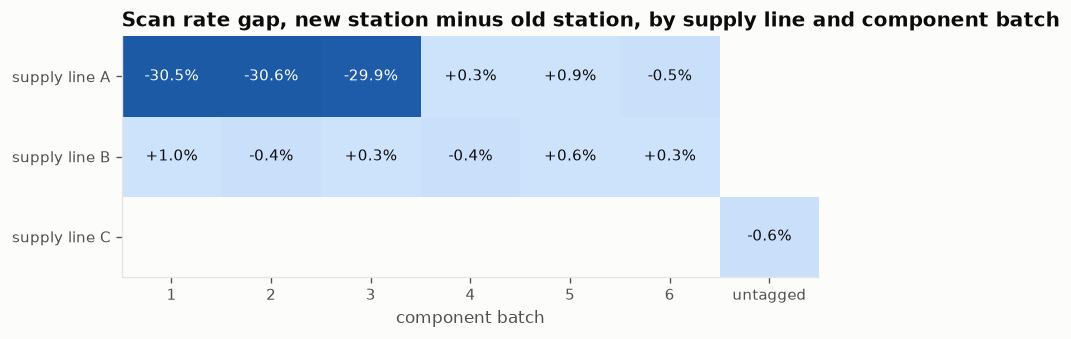

In [6]:
# Figure 1: new-minus-old scan-rate gap by supply line and component batch.
grid = (seg.table[seg.table["supply_line"] != "<all>"]
        .pivot(index="supply_line", columns="batch", values="gap")
        .reindex(index=["A", "B", "C"]))
grid = grid[[c for c in ["1", "2", "3", "4", "5", "6", "untagged"] if c in grid.columns]]
fig, ax = plt.subplots(figsize=(7.5, 2.6))
mat = np.ma.masked_invalid(-grid.to_numpy(dtype=float))  # loss magnitude, one hue light->dark
cmap = BLUE_CMAP.copy()
cmap.set_bad(PALETTE["surface"])  # cells that do not exist (supply line C has no batch) stay blank
im = ax.imshow(mat, cmap=cmap, vmin=0, vmax=0.4, aspect="auto")
grid = grid.rename(index={"A": "supply line A", "B": "supply line B", "C": "supply line C"})
ax.set_xticks(range(grid.shape[1]), grid.columns)
ax.set_yticks(range(grid.shape[0]), grid.index)
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:+.1%}" if abs(v) > 1e-9 else "0",
                    ha="center", va="center", fontsize=9,
                    color="white" if -v > 0.2 else PALETTE["ink"])
ax.set_title("Scan rate gap, new station minus old station, by supply line and component batch")
ax.set_xlabel("component batch")
fig.savefig(FIG / "fig1_scan_gap_by_supply_line.png")
plt.show()

The loss is confined to supply line A on component batches 1 to 3, on the new-station side only, at roughly a third of those products. Every other cell is at parity. The monitoring table the plant team publishes (`scan_log_health`, arms pooled) shows the same cells losing scans, which is the clue an investigator would take to the scanner engineers: the redesigned station's scanner initialises after the first pass on older component batches and the scan is lost when the product moves off the station within the first second. The plant sees products reaching the scanner only as these aggregate counts per supply line, batch and day; there is no product-level plant-side log to re-trigger the analysis on.

In [7]:
(telemetry.assign(older_batch=lambda d: (d["supply_line"] == "A")
                  & batch_below_check(d["batch"].to_numpy(), "4"))
 .groupby(["supply_line", "older_batch"])["event_loss_rate"].mean().round(4).rename("mean event loss rate"))

supply_line  older_batch
A            False          0.0000
             True           0.1777
B            False          0.0000
C            False          0.0000
Name: mean event loss rate, dtype: float64

## Step 4: invariants on the routed and on the logged-scan population

Pre-treatment attributes that randomisation should have balanced: supply line mix, batch mix, country mix, and the 28-day pre-period finished-product count. Run twice: on everything routed, and on the population the dashboard actually compares.

In [8]:
assigned_pop = assignments.merge(products, on="product_id")
scanned_pop = scanned_products.merge(products, on="product_id")
metrics = ["supply_line", "batch", "country", "pre_period_finished_28d"]
inv_assigned = invariant_check(assigned_pop, arm_col="arm", metric_cols=metrics, level="assigned",
                               treatment_arm="treatment", control_arm="control")
inv_scanned = invariant_check(scanned_pop, arm_col="arm", metric_cols=metrics, level="exposed",
                              treatment_arm="treatment", control_arm="control")
cols = ["metric", "kind", "difference", "p_value", "flag"]
pd.concat({"assigned": inv_assigned.table[cols], "exposed": inv_scanned.table[cols]}).round(5)

metric         kind  difference  p_value   flag
assigned 0              supply_line  categorical     0.00293  0.26317  False
         1                    batch  categorical     0.00199  0.44095  False
         2                  country  categorical     0.00214  0.76082  False
         3  pre_period_finished_28d      numeric    -0.00094  0.88283  False
exposed  0              supply_line  categorical     0.01850  0.00000   True
         1                    batch  categorical     0.01574  0.00000   True
         2                  country  categorical     0.00290  0.44576  False
         3  pre_period_finished_28d      numeric     0.00756  0.27925  False

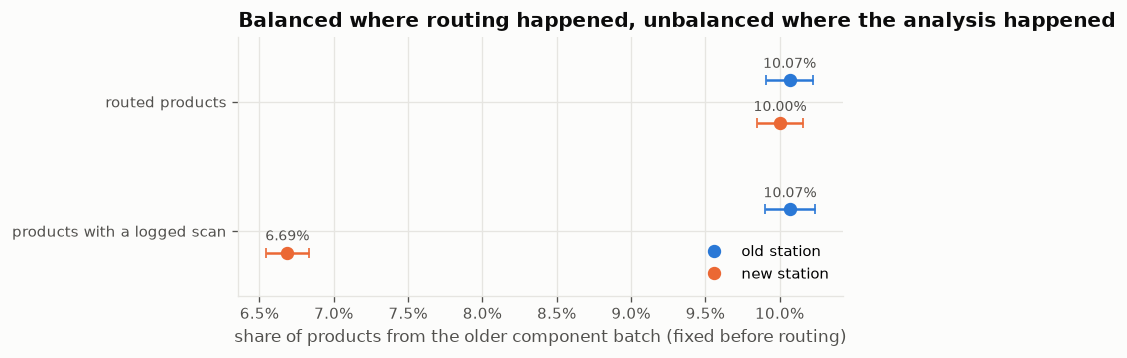

In [9]:
# Figure 2: the invariant that fails. Share of products in the affected cell (supply line A, batch < 4)
# per arm, on the assigned and on the exposed population, with 95% intervals.
def share_ci(mask):
    p, n = mask.mean(), len(mask)
    return p, 1.96 * np.sqrt(p * (1 - p) / n)

rows = []
for pop_name, pop in [("assigned", assigned_pop), ("exposed", scanned_pop)]:
    cell = (pop["supply_line"] == "A") & batch_below_check(pop["batch"].to_numpy(), "4")
    for arm in ["control", "treatment"]:
        p, h = share_ci(cell[pop["arm"] == arm])
        rows.append((pop_name, arm, p, h))
pts = pd.DataFrame(rows, columns=["population", "arm", "share", "half"])
ypos = {("assigned", "control"): 3.0, ("assigned", "treatment"): 2.4,
        ("exposed", "control"): 1.2, ("exposed", "treatment"): 0.6}
fig, ax = plt.subplots(figsize=(6.5, 2.8))
for _, r in pts.iterrows():
    yy = ypos[(r["population"], r["arm"])]
    ax.errorbar(r["share"], yy, xerr=r["half"], fmt="o", color=PALETTE[r["arm"]], capsize=3, lw=1.5)
    ax.text(r["share"], yy + 0.17, f"{r['share']:.2%}", ha="center", fontsize=8.5, color=PALETTE["ink2"])
ax.set_yticks([2.7, 0.9], ["routed products", "products with a logged scan"])
ax.set_ylim(0, 3.6)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.1%}")
ax.set_xlabel("share of products from the older component batch (fixed before routing)")
ax.set_title("Balanced where routing happened, unbalanced where the analysis happened")
ax.legend(handles=[plt.Line2D([], [], marker="o", color=PALETTE[a], ls="", label={"control": "old station", "treatment": "new station"}[a])
                   for a in ["control", "treatment"]], loc="lower right")
fig.savefig(FIG / "fig2_older_batch_share.png")
plt.show()

On the routed population every invariant is balanced. On the population with a logged scan the supply line and batch mix are flagged: the new-station arm has fewer older-batch products than the old-station arm, and that batch is the lowest-yielding one, so any outcome comparison on this population is tilted in the new station's favour.

The pre-period finished-product count moves in the expected direction but is **not** flagged, and the arithmetic below says why: the lost products are a small share of the new-station arm with a logged scan and differ from it by a fraction of a finished product, so the expected shift in the arm mean is little more than one standard error of the difference, and a test at a 0.001 threshold has almost no power there. A composition invariant (which products are here) catches the removal because the removed products all sit in one category; an outcome-proxy invariant (what those products did before) fires only when the removed group is very different from the rest. Run both, and never read a pass on the second as a clean bill of health.

In [10]:
# Why the pre-period invariant does not fire: expected shift versus its standard error.
exp_t = scanned_pop[scanned_pop["arm"] == "treatment"]
t_products = assigned_pop[assigned_pop["arm"] == "treatment"]
t_older = (t_products["supply_line"] == "A") & batch_below_check(t_products["batch"].to_numpy(), "4")
# Lost treatment products in excess of the arm-independent legacy-route share: estimated as the
# affected-cell products the scanned treatment arm is missing relative to control's scan rate.
ctl_products = assigned_pop[assigned_pop["arm"] == "control"]
ctl_older = (ctl_products["supply_line"] == "A") & batch_below_check(ctl_products["batch"].to_numpy(), "4")
ctl_rate_older = ctl_products.loc[ctl_older, "product_id"].isin(scanned_products["product_id"]).mean()
t_rate_older = t_products.loc[t_older, "product_id"].isin(scanned_products["product_id"]).mean()
excess_lost = (ctl_rate_older - t_rate_older) * t_older.sum()
# Removing k products from an arm of n + k moves its mean by k / (n + k) x (full mean - removed mean).
share_lost = excess_lost / (len(exp_t) + excess_lost)  # share of scanned treatment products
older_mean = t_products.loc[t_older, "pre_period_finished_28d"].mean()
arm_mean = exp_t["pre_period_finished_28d"].mean()
shift = share_lost * (arm_mean - older_mean)
sd = assigned_pop["pre_period_finished_28d"].std()
exp_c = scanned_pop[scanned_pop["arm"] == "control"]
se = sd * np.sqrt(1 / len(exp_t) + 1 / len(exp_c))
print(f"excess lost products: {excess_lost:,.0f} = {share_lost:.1%} of scanned treatment products "
      f"({excess_lost / len(t_products):.1%} of the treatment arm)")
realised_p = inv_scanned.table.set_index("metric").loc["pre_period_finished_28d", "p_value"]
print(f"realised pre-period test on the logged-scan population: p = {realised_p:.3f} (threshold 0.001)")
print(f"affected-cell mean pre-period finishes {older_mean:.2f} vs logged-scan treatment arm {arm_mean:.2f}")
print(f"expected shift in the arm mean {shift:.4f}; SE of the difference {se:.4f}; ratio {shift / se:.1f}")

excess lost products: 4,225 = 3.6% of scanned treatment products (3.0% of the treatment arm)
realised pre-period test on the logged-scan population: p = 0.279 (threshold 0.001)
affected-cell mean pre-period finishes 0.36 vs logged-scan treatment arm 0.59
expected shift in the arm mean 0.0082; SE of the difference 0.0070; ratio 1.2


## Step 5: outcome-event completeness

Finished-product records reach the data warehouse with a 0 to 36 hour delay. Two questions: is the delay the same in both arms, and how much of the outcome is missing at the moment the dashboard was produced?

In [11]:
lag_dashboard = event_arrival_lag(finished_products, assignments, event_time_col="finished_at",
                                  received_time_col="received_at", analysis_time=dashboard_time, user_col="product_id")
lag_final = event_arrival_lag(finished_products, assignments, event_time_col="finished_at",
                              received_time_col="received_at", analysis_time=analysis_time, user_col="product_id")
print(f"KS test between arms: D={lag_dashboard.ks_statistic:.4f}, p={lag_dashboard.ks_p_value:.3f}, "
      f"differential={lag_dashboard.differential}")
open_window = (assignments["assigned_at"] + window > dashboard_time).groupby(assignments["arm"]).mean()
print("share of products whose 7-day window had not closed at dashboard time:",
      open_window.round(3).to_dict())
placed = finished_products[finished_products["finished_at"] <= dashboard_time]
print(f"finishes recorded by dashboard time but not yet received: {(placed['received_at'] > dashboard_time).mean():.1%} "
      f"of {len(placed):,}")
pd.concat({"at dashboard time": lag_dashboard.table.set_index("arm"),
           "at analysis time": lag_final.table.set_index("arm")}).round(3)

KS test between arms: D=0.0217, p=0.236, differential=False


share of products whose 7-day window had not closed at dashboard time: {'control': 0.499, 'treatment': 0.501}
finishes recorded by dashboard time but not yet received: 5.1% of 8,548


n_events  mean_lag_h  median_lag_h  p90_lag_h  \
                  arm                                                        
at dashboard time control        4458      18.100        18.221     32.530   
                  treatment      4532      17.821        17.581     32.211   
at analysis time  control        4458      18.100        18.221     32.530   
                  treatment      4532      17.821        17.581     32.211   

                             max_lag_h  share_unavailable_at_analysis  
                  arm                                                  
at dashboard time control       36.000                          0.101  
                  treatment     35.998                          0.095  
at analysis time  control       36.000                          0.000  
                  treatment     35.998                          0.000

The delay is identical across arms (non-differential) and it creates no SRM, so a sample-ratio check would never see it. At dashboard time about one finished product in twenty already completed had not arrived (the table's `share_unavailable_at_analysis` column divides by every eventual finished product, including those completed later, and so reads higher), and half of all products had not finished their 7-day outcome window. Neither problem biases the comparison between arms, because both hit the arms equally; both bias the *level* of the metric downward and shrink the effective sample. The correct handling is to wait for `analysis_time`, or to restrict to cohorts whose window has closed. This notebook uses `analysis_time`.

## Step 6: the estimate, on each population

Outcome: finished within 7 days of routing. Four numbers: what the dashboard showed on day 14 (products with a logged scan, finished products received by `dashboard_time`); the same logged-scan comparison on complete data (finished products received by `analysis_time`); the same comparison with the older component batch (supply line A, batches 1 to 3) removed from both arms, a pre-treatment exclusion that leaves a population whose logging is intact; and the pre-registered intent-to-treat estimate on the routed population at `analysis_time`.

In [12]:
o_all = finished_products.merge(assignments[["product_id", "assigned_at"]], on="product_id")
o = o_all[(o_all["finished_at"] >= o_all["assigned_at"])
          & (o_all["finished_at"] < o_all["assigned_at"] + window)
          & (o_all["received_at"] <= analysis_time)]
converters = set(o["product_id"])

def counts(pop):
    out = {}
    for arm in ["treatment", "control"]:
        ids = pop.loc[pop["arm"] == arm, "product_id"]
        out[arm] = (int(ids.isin(converters).sum()), int(len(ids)))
    return out

c_assigned, c_scanned = counts(assignments), counts(scanned_products)
ctl = assigned_pop[assigned_pop["arm"] == "control"].assign(converted=lambda d: d["product_id"].isin(converters))
ctl_older = (ctl["supply_line"] == "A") & batch_below_check(ctl["batch"].to_numpy(), "4")
print(f"control-arm yield, affected cell {ctl.loc[ctl_older, 'converted'].mean():.4%} "
      f"vs rest {ctl.loc[~ctl_older, 'converted'].mean():.4%} "
      f"(ratio {ctl.loc[ctl_older, 'converted'].mean() / ctl.loc[~ctl_older, 'converted'].mean():.2f})")
itt = difference_in_proportions(*c_assigned["treatment"], *c_assigned["control"],
    estimand="ITT difference in 7-day yield among eligible products", analysis_unit="product", population="routed")
naive = difference_in_proportions(*c_scanned["treatment"], *c_scanned["control"],
    estimand="difference in 7-day yield among products with a logged scan", analysis_unit="product", population="logged scans")
o_dash = o_all[(o_all["finished_at"] >= o_all["assigned_at"])
              & (o_all["finished_at"] < o_all["assigned_at"] + window)
              & (o_all["received_at"] <= dashboard_time)]
yielding_dash = set(o_dash["product_id"])
c_dash = {arm: (int(ids.isin(yielding_dash).sum()), int(len(ids)))
          for arm, ids in ((a, scanned_products.loc[scanned_products["arm"] == a, "product_id"])
                           for a in ["treatment", "control"])}
dashboard = difference_in_proportions(*c_dash["treatment"], *c_dash["control"],
    estimand="difference in yield among products with a logged scan, as received by day 14",
    analysis_unit="product", population="logged scans")
outside = scanned_products.merge(products[["product_id", "supply_line", "batch"]], on="product_id")
outside = outside[~((outside["supply_line"] == "A")
                    & batch_below_check(outside["batch"].to_numpy(), "4"))]
excl = difference_in_proportions(*counts(outside)["treatment"], *counts(outside)["control"],
    estimand="difference in yield among logged-scan products outside the affected segment",
    analysis_unit="product", population="logged scans, affected segment excluded")
print("dashboard, day 14        :", dashboard.summary())
print("logged, complete data    :", naive.summary())
print("logged, segment removed  :", excl.summary())
print("ITT, complete data       :", itt.summary())

control-arm yield, affected cell 1.7362% vs rest 3.3422% (ratio 0.52)


dashboard, day 14        : logged scans population, product level: treatment 3.0356% vs control 2.8528%; difference +0.1828% [+0.0457%, +0.3199%], relative +6.41% [+1.57%, +11.48%], p=0.00892.
logged, complete data    : logged scans population, product level: treatment 3.3416% vs control 3.1666%; difference +0.1750% [+0.0311%, +0.3188%], relative +5.53% [+0.96%, +10.30%], p=0.0171.
logged, segment removed  : logged scans, affected segment excluded population, product level: treatment 3.4531% vs control 3.3252%; difference +0.1278% [-0.0254%, +0.2811%], relative +3.84% [-0.75%, +8.65%], p=0.102.
ITT, complete data       : routed population, product level: treatment 3.2409% vs control 3.1806%; difference +0.0604% [-0.0702%, +0.1910%], relative +1.90% [-2.16%, +6.13%], p=0.365.


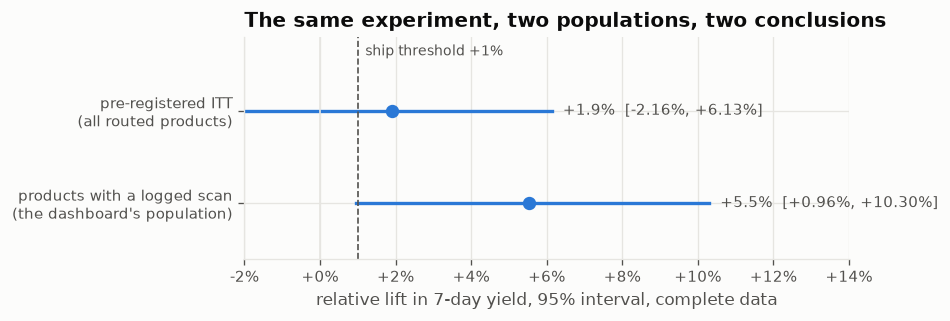

In [13]:
# Figure 3: relative lift with 95% interval on the two populations, against the ship threshold.
fig, ax = plt.subplots(figsize=(6.5, 2.4))
# Both rows are the same contrast (treatment vs control) on different populations, so they
# share one colour; the row label carries identity.
for yy, r in enumerate([naive, itt]):  # both on complete data, at analysis_time
    lo, hi = r.relative_confidence_interval
    ax.plot([lo, hi], [yy, yy], color=PALETTE["control"], lw=2)
    ax.plot(r.relative_lift, yy, "o", color=PALETTE["control"])
    ax.text(hi + 0.003, yy, f"{r.relative_lift:+.1%}  [{lo:+.2%}, {hi:+.2%}]", va="center", fontsize=9, color=PALETTE["ink2"])
ax.axvline(threshold, color=PALETTE["threshold"], ls="--", lw=1)
ax.text(threshold + 0.002, 1.6, f"ship threshold {threshold:+.0%}", fontsize=8.5, color=PALETTE["ink2"], ha="left")
ax.axvline(0, color=PALETTE["grid"], lw=1)
ax.set_yticks([0, 1], ["products with a logged scan\n(the dashboard's population)", "pre-registered ITT\n(all routed products)"])
ax.set_xlim(-0.02, 0.14)
ax.set_ylim(-0.6, 1.8)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.0%}")
ax.set_xlabel("relative lift in 7-day yield, 95% interval, complete data")
ax.set_title("The same experiment, two populations, two conclusions")
fig.savefig(FIG / "fig3_naive_vs_itt.png")
plt.show()

## Step 7: guardrails and decision

Each guardrail has a pre-declared non-inferiority margin in `config.yaml` (a business input, like the ship threshold), applied to the new-station-minus-old-station difference: it passes when the upper 95% bound is at or below the margin, breaches when the lower 95% bound is above it, and is inconclusive otherwise.

The cycle-time guardrail is measured by the station's own timing event. Where the scan was lost, so was the cycle-time measurement, and products on the legacy manual route never have one. The estimator is the ratio of new-station to old-station p95 cycle time over each arm's measured runs, with a 95% interval from a bootstrap that resamples products (a product contributes about 1.3 runs, so runs are clustered). It is computed overall and within the older component batch. In this simulation the loss is random within the older batch, so the measured older-batch runs are a random sample and the batch estimate is unbiased here. In a real incident the mechanism described (products moving off the station within the first second) ties the loss to behaviour, and the measured runs could then misrepresent the batch; that unverified mechanism is what keeps the cycle-time guardrail a blocker for the older component batch.

In [14]:
lat = attempts.merge(assignments[["product_id", "arm"]], on="product_id").merge(products[["product_id", "supply_line", "batch"]], on="product_id")
lat["older_batch"] = (lat["supply_line"] == "A") & batch_below_check(lat["batch"].to_numpy(), "4")
cov = lat.groupby(["arm", "older_batch"])["cycle_time_ms"].agg(runs="size", measured=lambda s: s.notna().mean(), p95=lambda s: s.quantile(0.95))
print(cov.round(3))
margins = config["decision_rule"]["guardrails"]
p95 = lat.dropna(subset=["cycle_time_ms"]).groupby("arm")["cycle_time_ms"].quantile(0.95)
print(f"p95 cycle time on measured runs: treatment {p95['treatment']:.0f} ms, control "
      f"{p95['control']:.0f} ms ({p95['treatment'] / p95['control'] - 1:+.1%})")


# Defined here, outside the package: product-clustered bootstrap of the p95 ratio.
def p95_ratio_interval(frame, n_boot=2000, seed=20260928):
    # Product-clustered bootstrap of the treatment/control p95 ratio on measured runs.
    rng = np.random.default_rng(seed)
    m = frame.dropna(subset=["cycle_time_ms"])
    per_arm = {}
    for arm in ("treatment", "control"):
        g = m[m["arm"] == arm]
        codes, uniq = pd.factorize(g["product_id"])
        order = np.argsort(codes, kind="stable")
        values = g["cycle_time_ms"].to_numpy()[order]
        starts = np.searchsorted(codes[order], np.arange(len(uniq)))
        per_arm[arm] = (values, starts, np.diff(np.append(starts, len(values))))
    ratios = []
    for _ in range(n_boot):
        q = {}
        for arm, (values, starts, sizes) in per_arm.items():
            pick = rng.integers(0, len(starts), len(starts))
            k = sizes[pick]
            idx = np.repeat(starts[pick] - np.cumsum(np.r_[0, k[:-1]]), k) + np.arange(k.sum())
            q[arm] = np.quantile(values[idx], 0.95)
        ratios.append(q["treatment"] / q["control"] - 1)
    point = m[m.arm == "treatment"]["cycle_time_ms"].quantile(0.95) / m[m.arm == "control"]["cycle_time_ms"].quantile(0.95) - 1
    return point, np.quantile(ratios, 0.025), np.quantile(ratios, 0.975)


# Defined here, outside the package: the pre-declared verdict rule.
def guardrail_verdict(upper, lower, margin):
    if upper <= margin:
        return "pass"
    return "breach" if lower > margin else "inconclusive"


m_lat = margins["cycle_time_p95_max_increase_relative"]
for label, frame in (("all segments", lat), ("affected segment", lat[lat["older_batch"]])):
    point, lo, hi = p95_ratio_interval(frame)
    print(f"p95 ratio, {label}: {point:+.1%} [{lo:+.1%}, {hi:+.1%}] against margin +{m_lat:.0%}: "
          f"{guardrail_verdict(hi, lo, m_lat)} (measured share of affected treatment runs "
          f"{lat.loc[lat['older_batch'] & (lat['arm'] == 'treatment'), 'cycle_time_ms'].notna().mean():.1%})")
measured = lat.dropna(subset=["cycle_time_ms"])
print("affected-segment share of measured runs by arm:",
      measured.groupby("arm")["older_batch"].mean().round(4).to_dict(),
      "(the overall ratio mixes segments in different proportions by arm; the segments' p95s are",
      "within about 1% of each other here, so the mix does not move it)")

                         runs  measured      p95
arm       older_batch                           
control   False        163779     0.851  2134.20
          True          18360     0.852  2117.00
treatment False        163785     0.851  2139.80
          True          18107     0.547  2118.08


p95 cycle time on measured runs: treatment 2138 ms, control 2133 ms (+0.3%)


p95 ratio, all segments: +0.3% [-0.2%, +0.8%] against margin +5%: pass (measured share of affected treatment runs 54.7%)


p95 ratio, affected segment: +0.1% [-1.6%, +1.8%] against margin +5%: pass (measured share of affected treatment runs 54.7%)
affected-segment share of measured runs by arm: {'control': 0.101, 'treatment': 0.0663} (the overall ratio mixes segments in different proportions by arm; the segments' p95s are within about 1% of each other here, so the mix does not move it)


The packing-step guardrail is measured at the product level, the unit of randomisation: the share of routed products with at least one packing-step run that raised a station error, through the station or the legacy route. A run is a visit to the packing step, not a finished product, so most runs end without one. The denominator is every routed product, so no post-routing filter enters it. (The per-run error rate is a ratio metric whose variance needs the delta method; that is Case 02's subject.) Runs per product are reported by arm, because a redesign that changes how often products revisit the step would move "any error" mechanically.

In [15]:
per_product = attempts.groupby("product_id").agg(any_error=("packing_step_error", "any"),
                                           n_runs=("packing_step_error", "size"))
pf = assignments[["product_id", "arm"]].merge(per_product, on="product_id", how="left")
pf["any_error"] = pf["any_error"].fillna(False).astype(bool)
pf["n_runs"] = pf["n_runs"].fillna(0)
print("packing-step runs per routed product by arm:", pf.groupby("arm")["n_runs"].mean().round(4).to_dict())
pf_counts = {arm: (int(g["any_error"].sum()), int(len(g))) for arm, g in pf.groupby("arm")}
payment = difference_in_proportions(*pf_counts["treatment"], *pf_counts["control"],
    estimand="difference in share of routed products with a packing-step error", analysis_unit="product",
    population="assigned")
print(payment.summary())
m = margins["packing_step_error_max_increase_absolute"]
print(f"margin +{m * 100:.1f} points absolute: {guardrail_verdict(payment.confidence_interval[1], payment.confidence_interval[0], m)}")

packing-step runs per routed product by arm: {'control': 1.2995, 'treatment': 1.3008}
assigned population, product level: treatment 5.1246% vs control 5.1568%; difference -0.0322% [-0.1958%, +0.1313%], relative -0.63% [-3.74%, +2.59%], p=0.699.
margin +0.3 points absolute: pass


The return guardrail has a clock of its own. A return can arrive up to 14 days after the finished product, so at `analysis_time` the return window is still open for every finished product completed in the previous 14 days. Counting the returns seen so far over all finished products understates the rate, and a change that shifts returns later would look better than it is. The guardrail is therefore computed only on finished products whose 14-day window has closed by `analysis_time`. It is breach-only: a breach of its +10% margin stops the launch, and a pass is not required, because at this cohort size a +10% margin passes a harmless change only about 18% of the time. Two dates matter: the design date, fixed before the experiment (the last possible finished product from the interim cohorts, at the end of the last such product's outcome window, plus 14 days), and the date this run's last actual finished product matures. The matured cohort consists of early finished products, from products taken in during about the first 8.4 days, so it says nothing yet about the later intake. The slowest guardrail sets the earliest date on which a complete decision can be taken. (With one finished product per yielding product, finished product and product coincide. Conditioning on having been finished is a post-treatment selection; it is harmless here only because the simulated effect on returns is zero, and the README flags it.)

In [16]:
return_window = pd.Timedelta(days=14)
ro = finished_products.merge(assignments[["product_id", "arm"]], on="product_id")
ro = ro[ro["received_at"] <= analysis_time]
matured = ro["finished_at"] + return_window <= analysis_time
seen = ro["returned_at"].notna() & (ro["returned_at"] <= analysis_time)
design_date = dashboard_time + window + return_window
fully_measured = ro["finished_at"].max() + return_window
enrolled = ro.loc[matured, "product_id"].map(assignments.set_index("product_id")["assigned_at"])
print(f"finished products visible at analysis_time: {len(ro):,}; return window closed for {matured.mean():.1%}")
print(f"return guardrail complete by design for the interim cohorts on {design_date:%Y-%m-%d} "
      f"({(design_date - analysis_time) / pd.Timedelta(days=1):.1f} days after data-complete); this run's last "
      f"finished product matures on {fully_measured:%Y-%m-%d %H:%M}")
print(f"matured finishes come from products routed up to {enrolled.max():%Y-%m-%d %H:%M}")
naive_rate = seen.mean()
mat = ro[matured].assign(returned=seen[matured])
r_counts = {arm: (int(g["returned"].sum()), int(len(g))) for arm, g in mat.groupby("arm")}
returns = difference_in_proportions(*r_counts["treatment"], *r_counts["control"],
    estimand="difference in 14-day return rate per finished product", analysis_unit="finished product",
    population="finished products whose return window closed by analysis_time")
print(f"return rate counting open windows (understated): {naive_rate:.2%}; matured cohort: "
      f"treatment {returns.rate_treatment:.2%}, control {returns.rate_control:.2%}")
print(returns.summary())
m = margins["return_rate_max_increase_relative"]
lo, hi = returns.relative_confidence_interval
verdict = guardrail_verdict(hi, lo, m)
print(f"margin +{m:.0%} relative (breach-only): {verdict}; "
      f"{'breach' if verdict == 'breach' else 'no breach on the matured cohort so far'}")

finished products visible at analysis_time: 8,990; return window closed for 54.8%
return guardrail complete by design for the interim cohorts on 2026-04-06 (12.5 days after data-complete); this run's last finished product matures on 2026-04-04 11:31
matured finishes come from products routed up to 2026-03-10 10:26
return rate counting open windows (understated): 4.63%; matured cohort: treatment 5.04%, control 4.98%
finished products whose return window closed by analysis_time population, finished product level: treatment 5.0444% vs control 4.9755%; difference +0.0689% [-1.1490%, +1.2868%], relative +1.38% [-20.50%, +29.29%], p=0.912.
margin +10% relative (breach-only): inconclusive; no breach on the matured cohort so far


### Decision blockers

| Blocker | Status |
|---|---|
| Routing issue | none: routing-level counts and invariants pass |
| Scan measurement issue | **open**: new-station scan lost for supply line A, batches 1 to 3 |
| Outcome logging issue | non-differential records delay; handled by using `analysis_time` |
| Differential missingness | **open**, on scans only |
| Guardrail unmeasurable or not yet mature | **open**: cycle time missing for about 45% of affected new-station runs (15% elsewhere) under an unverified loss mechanism; return guardrail read on the matured cohort only until its window closes |
| Duration insufficient for delayed outcomes | none once `analysis_time` is used |

### Recommendation

Analysing triggered (logged-scan) products is standard practice and valid when the trigger fires independently of arm; it is what gives triggered analyses their sensitivity. Here the trigger event itself is lost differentially, so the population with a logged scan is no longer a random subset of the routed one and the dashboard's estimate is biased upward: the products it lost were the lowest-yielding new-station products. The intent-to-treat estimate is valid, and on its own its interval falls in the rule's continue zone; under the sequenced rule the open blockers come first, so the rule gives no decision until they are resolved. Removing the older component batch from both arms gives a valid logged-scan estimate for products that reach the scanner outside that batch (about 76% of eligible products); its lift is on the triggered scale, so the +1.0% ITT floor does not apply to it directly, and it describes a different population from the one the decision is about. The blockers stand regardless of the estimates: the scan pipeline, the cycle-time guardrail and the return guardrail's maturity. Recommendation: do not ship; stop the experiment, whose remaining intake carries the same defect; fix the scanner on the older component batch (supply line A, batches 1 to 3); run an A/A on the scan pipeline to confirm parity; rerun the experiment under the same pre-declared design with the fix in place. Full memo: `decision_memo.md`.

### What this case establishes

The standard sample-ratio check passed, and the failure lived one level down, in the population the analysis was run on. Validity belongs to the comparison, and the first question in any review is whether the analysed population is the randomised one.